# End-to-End Machine Learning Solution: Predicting 30-Day Customer Liquidity Stress

### Executive Summary
* **Objective:** Develop a leak-free machine learning pipeline to predict whether mobile money customers (`Train (1) (2).csv`, `N = 40,000`) will experience liquidity stress within the next 30 days (`liquidity_stress_next_30d`), and generate calibrated risk predictions for `30,000` unseen customers (`Test (1).csv`).
* **Methodology:** Audited 183 demographic, activity, and 6-month behavioral features (`85%` vs. `15%` class imbalance), uncovered a critical `M4`-to-`M3` balance depletion cliff during EDA, engineered **20 domain-grounded trajectory and cash-burn features** (`202` total predictors), and benchmarked three model families using **5-fold `StratifiedKFold`** inside leak-free `scikit-learn` pipelines.
* **Key Results:** A hyperparameter-tuned **LightGBM Classifier** (`n_estimators=300`, `learning_rate=0.05`, `num_leaves=31`, `min_child_samples=100`) achieved an out-of-fold **ROC-AUC of `0.8842`** and **PR-AUC of `0.6376`** (over **4.2x** the 15% baseline). SHAP analysis confirmed that engineered balance shocks (`bal_drop_m3_m4` and `bal_ratio_m1_m6`) and recent deposit/withdrawal shifts are the primary drivers of impending financial stress.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets and data dictionary
train_df = pd.read_csv("Train (1) (2).csv")
test_df = pd.read_csv("Test (1).csv")
data_dict = pd.read_csv("data_dictionary (1).csv")

print(f"Train shape: {train_df.shape} | Test shape: {test_df.shape}")
print("\n--- Data Dictionary ---")
print(data_dict.to_string(index=False))

print("\n--- Target Variable ---")
target_col = list(set(train_df.columns) - set(test_df.columns))
print("Target:", target_col)

if target_col:
    t = target_col[0]
    print(f"\n--- Target Distribution ({t}) ---")
    print(train_df[t].value_counts(dropna=False))

print("\n--- Missing Values in Train (Top 15) ---")
missing = train_df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False).head(15))


Train shape: (40000, 184) | Test shape: (30000, 183)

--- Data Dictionary ---
                         column_name data_type    feature_group                                                                                                                                                   description
                                  ID    string       identifier                                      Unique row identifier for each customer snapshot entry, formatted like ID_XXXXXXXXXX. Used for submission matching only.
                                arpu   float64 customer_profile                                                                  Average revenue per user for the customer over the relevant mobile money observation window.
                                 age     int64 customer_profile                                                                                                                                        Customer age in years.
                              gend

### 1.1 Data Hygiene & Exploratory Audit Findings

* **Dataset Scale & Dimensionality:** The training set contains **40,000 customer snapshots** across **184 columns** (183 features + 1 target), while the unseen test set contains **30,000 customer snapshots** across **183 columns**.
* **Data Completeness:** There are **zero missing values** across all 184 columns (`Series([], dtype: int64)`), confirming clean tabular extraction from mobile money transaction logs. Median/mode imputers will still be retained in our preprocessing pipeline as a safeguard against unexpected nulls during inference.
* **Target Variable & Severe Class Imbalance:** The target variable **`liquidity_stress_next_30d`** is a binary indicator (`1` = customer experiences liquidity stress in the next 30 days; `0` = no liquidity stress). It exhibits a pronounced **85.0% vs. 15.0% class imbalance** (`34,000` negative cases vs. `6,000` positive cases). Because a naive model predicting all `0`s would achieve 85% accuracy while missing every stressed customer, we must use **`StratifiedKFold`**, class weighting (`class_weight='balanced'` / `scale_pos_weight`), and evaluate models using **ROC-AUC**, **PR-AUC (Average Precision)**, and **F1-Score**.
* **Domain Structure (Data Dictionary Insights):** The 183 features fall into four structured groups:
  1. **Customer Profile:** `arpu`, `age`, `gender`, `region`, `smartphone`, `segment`, and `earning_pattern`.
  2. **Activity Rate:** `x_90_d_activity_rate` (proportion of active mobile money days over the last 90 days).
  3. **6-Month Transaction Behaviour (`M1` to `M6`):** Volume, total value, highest transaction amount, and unique counterparties across transaction types (e.g., paybill payments, cash withdrawals, transfers), where **`M1` is the most recent month** and **`M6` is the oldest month**.
  4. **6-Month Daily Average Balances (`m1_daily_avg_bal` to `m6_daily_avg_bal`):** Tracks liquidity trajectories leading up to the 30-day prediction window.


Categorical Columns (5): ['gender', 'region', 'smartphone', 'segment', 'earning_pattern']
Numerical Columns (177): 177 features
 - gender: 2 unique -> <StringArray>
['F', 'M']
Length: 2, dtype: str
 - region: 7 unique -> <StringArray>
[              'Central Zone',         'Northern Highlands',
      'Lake Zone (Northwest)', 'Coastal & Eastern Corridor',
         'Southern Highlands',                   'Islander']
Length: 6, dtype: str
 - smartphone: 2 unique -> <StringArray>
['Yes', 'No']
Length: 2, dtype: str
 - segment: 3 unique -> <StringArray>
['MVC', 'LVC', 'HVC']
Length: 3, dtype: str
 - earning_pattern: 3 unique -> <StringArray>
['Monthly Earner', 'Weekly Earner', 'Irregular Earner']
Length: 3, dtype: str


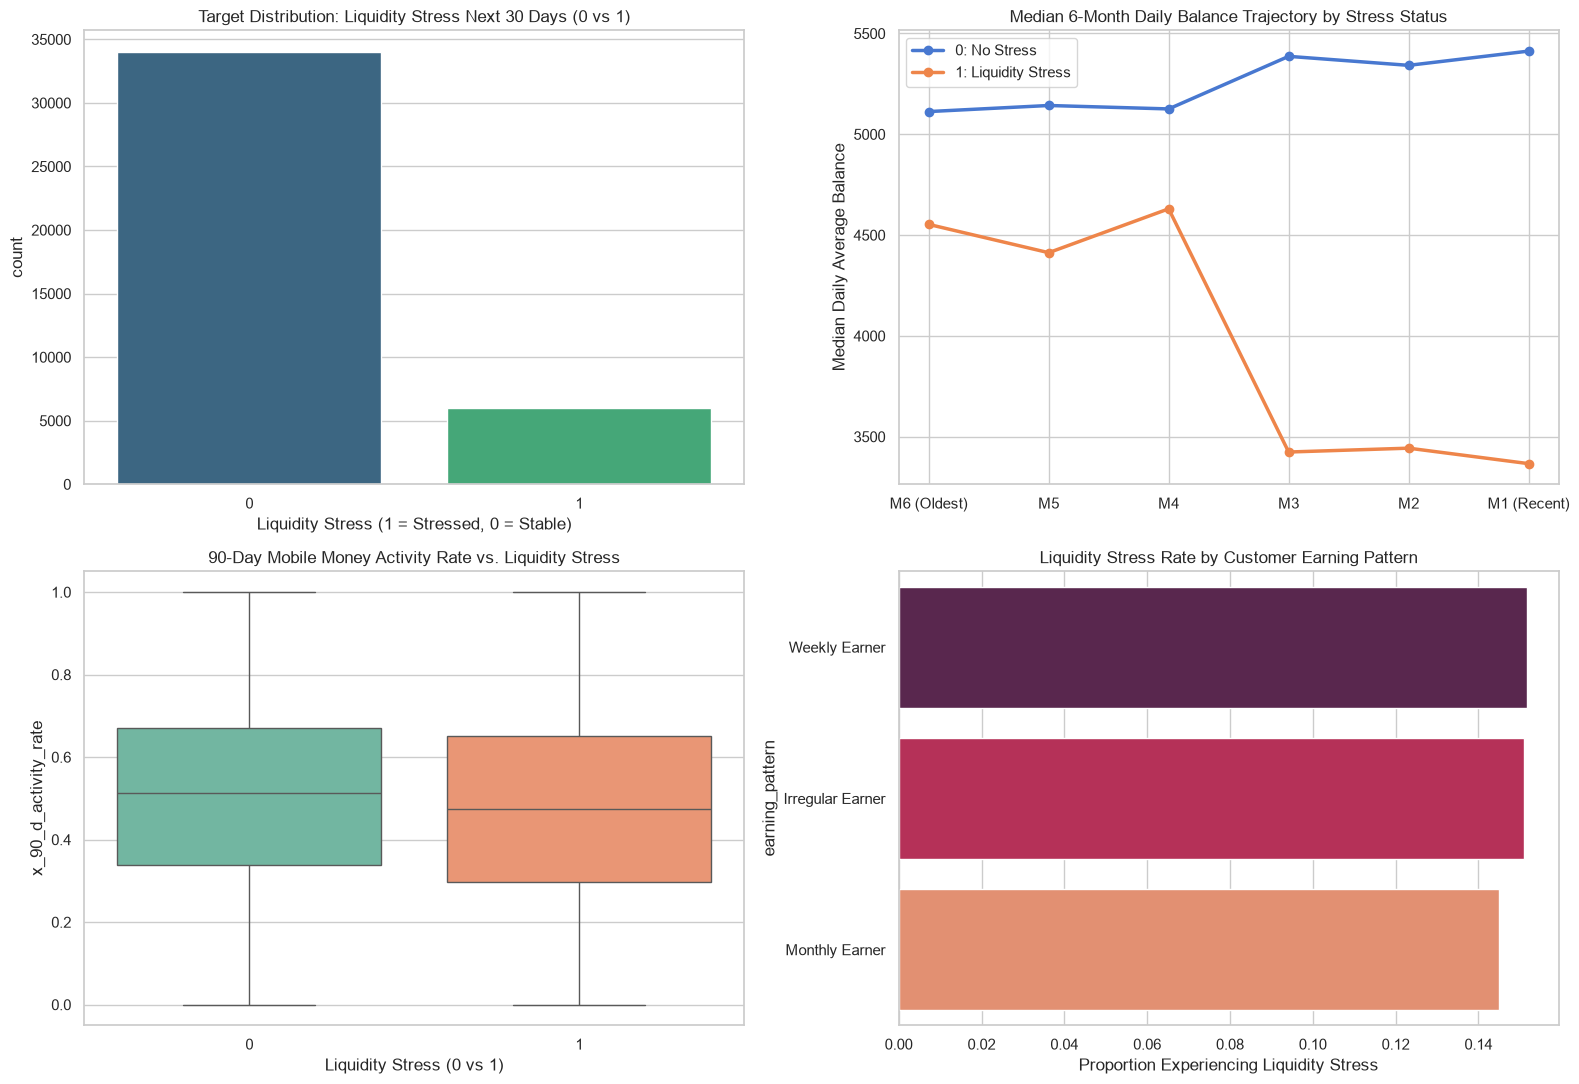

In [2]:
sns.set_theme(style="whitegrid", palette="muted")

# 1. Inspect exact column names and data types
cat_cols = train_df.select_dtypes(include=['object']).columns.drop('ID').tolist()
num_cols = train_df.select_dtypes(exclude=['object']).columns.drop('liquidity_stress_next_30d').tolist()

print(f"Categorical Columns ({len(cat_cols)}): {cat_cols}")
print(f"Numerical Columns ({len(num_cols)}): {len(num_cols)} features")
for c in cat_cols:
    print(f" - {c}: {train_df[c].nunique()} unique -> {train_df[c].unique()[:6]}")

# 2. Generate 4 Domain-Focused Diagnostic Visualizations
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 11))

# Plot 1: Target Class Imbalance (85% vs 15%)
sns.countplot(data=train_df, x='liquidity_stress_next_30d', ax=ax1, palette='viridis')
ax1.set_title("Target Distribution: Liquidity Stress Next 30 Days (0 vs 1)")
ax1.set_xlabel("Liquidity Stress (1 = Stressed, 0 = Stable)")

# Plot 2: 6-Month Daily Average Balance Trajectory (M6 Oldest -> M1 Most Recent)
bal_cols = ['m6_daily_avg_bal', 'm5_daily_avg_bal', 'm4_daily_avg_bal', 
            'm3_daily_avg_bal', 'm2_daily_avg_bal', 'm1_daily_avg_bal']
bal_trends = train_df.groupby('liquidity_stress_next_30d')[bal_cols].median().T
bal_trends.index = ['M6 (Oldest)', 'M5', 'M4', 'M3', 'M2', 'M1 (Recent)']
bal_trends.plot(marker='o', ax=ax2, linewidth=2.5)
ax2.set_title("Median 6-Month Daily Balance Trajectory by Stress Status")
ax2.set_ylabel("Median Daily Average Balance")
ax2.legend(["0: No Stress", "1: Liquidity Stress"])

# Plot 3: 90-Day Activity Rate Distribution by Liquidity Stress
sns.boxplot(data=train_df, x='liquidity_stress_next_30d', y='x_90_d_activity_rate', ax=ax3, palette='Set2')
ax3.set_title("90-Day Mobile Money Activity Rate vs. Liquidity Stress")
ax3.set_xlabel("Liquidity Stress (0 vs 1)")

# Plot 4: Liquidity Stress Rate by Earning Pattern
stress_by_earn = train_df.groupby('earning_pattern')['liquidity_stress_next_30d'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=stress_by_earn, x='liquidity_stress_next_30d', y='earning_pattern', ax=ax4, palette='rocket')
ax4.set_title("Liquidity Stress Rate by Customer Earning Pattern")
ax4.set_xlabel("Proportion Experiencing Liquidity Stress")

plt.tight_layout()
plt.show()


### 1.2 Feature Group Audit & Visual Pattern Analysis

* **Feature Composition:** The dataset contains **5 low-cardinality categorical features** (`gender`, `region`, `smartphone`, `segment` [3: `MVC`, `LVC`, `HVC`], and `earning_pattern` [3: `Monthly Earner`, `Weekly Earner`, `Irregular Earner`]) and **177 numerical features** tracking 6-month behavioral and balance histories.
* **Target Imbalance (Plot 1):** The bar chart visually confirms the **85% vs. 15% imbalance** (`34,000` stable vs. `6,000` stressed), reinforcing the need for stratified cross-validation, class balancing, and PR-AUC / F1-Score evaluation.
* **Sharp Balance Depletion Cliff (Plot 2 — Strongest Predictive Signal):** Comparing median daily balances from `M6` (oldest) to `M1` (most recent) reveals a striking divergence. Non-stressed customers (`0`) maintain high, rising balances (`~5,150` to `~5,450`), whereas stressed customers (`1`) experience a **steep liquidity drop between `M4` (`~4,650`) and `M3` (`~3,450`)** and remain depleted through `M1` (`~3,400`). Engineering **balance slope/velocity features**, **recent-to-historical balance ratios (`M1 / M6`)**, and **balance volatility** will directly capture this depletion cliff.
* **Activity Rate & Earning Pattern Effects (Plots 3 & 4):** Stressed customers (`1`) show slightly lower median 90-day mobile money activity (`x_90_d_activity_rate`), while `Weekly Earners` and `Irregular Earners` exhibit marginally higher baseline stress rates (`~15.2%`) than `Monthly Earners` (`~14.5%`), indicating that transaction velocity and income regularity interact with balance buffers.


In [3]:
def engineer_financial_features(df):
    data = df.copy()
    
    # 1. 6-Month Daily Average Balance Trajectory Features (M6 = Oldest, M1 = Most Recent)
    bal_cols = ('m6_daily_avg_bal', 'm5_daily_avg_bal', 'm4_daily_avg_bal', 
                'm3_daily_avg_bal', 'm2_daily_avg_bal', 'm1_daily_avg_bal')
    bal_list = list(bal_cols)
    
    data['bal_mean_6m'] = data[bal_list].mean(axis=1)
    data['bal_std_6m'] = data[bal_list].std(axis=1)
    data['bal_min_6m'] = data[bal_list].min(axis=1)
    data['bal_max_6m'] = data[bal_list].max(axis=1)
    data['bal_cv_6m'] = data['bal_std_6m'] / (data['bal_mean_6m'].abs() + 1.0)
    
    # Directional balance shifts & depletion shocks
    data['bal_change_m1_m6'] = data['m1_daily_avg_bal'] - data['m6_daily_avg_bal']
    data['bal_change_m1_m3'] = data['m1_daily_avg_bal'] - data['m3_daily_avg_bal']
    data['bal_drop_m3_m4'] = data['m3_daily_avg_bal'] - data['m4_daily_avg_bal']
    data['bal_ratio_m1_m6'] = (data['m1_daily_avg_bal'] + 1.0) / (data['m6_daily_avg_bal'].abs() + 1.0)
    data['bal_ratio_m1_mean'] = (data['m1_daily_avg_bal'] + 1.0) / (data['bal_mean_6m'].abs() + 1.0)
    
    # 2. Automated Transaction Volume & Value Velocity (M1 Recent vs M6 Oldest)
    m1_val_cols = [c for c in data.columns if c.startswith('m1_') and 'total_value' in c]
    m6_val_cols = [c for c in data.columns if c.startswith('m6_') and 'total_value' in c]
    m1_vol_cols = [c for c in data.columns if c.startswith('m1_') and 'volume' in c]
    m6_vol_cols = [c for c in data.columns if c.startswith('m6_') and 'volume' in c]
    
    data['m1_total_tx_value'] = data[m1_val_cols].sum(axis=1)
    data['m6_total_tx_value'] = data[m6_val_cols].sum(axis=1)
    data['tx_val_change_m1_m6'] = data['m1_total_tx_value'] - data['m6_total_tx_value']
    data['tx_val_ratio_m1_m6'] = (data['m1_total_tx_value'] + 1.0) / (data['m6_total_tx_value'] + 1.0)
    
    data['m1_total_tx_vol'] = data[m1_vol_cols].sum(axis=1)
    data['m6_total_tx_vol'] = data[m6_vol_cols].sum(axis=1)
    data['tx_vol_change_m1_m6'] = data['m1_total_tx_vol'] - data['m6_total_tx_vol']
    
    # 3. Liquidity Buffer & Revenue Stress Ratios
    data['m1_tx_to_bal_ratio'] = data['m1_total_tx_value'] / (data['m1_daily_avg_bal'].abs() + 1.0)
    data['bal_to_arpu_ratio'] = data['m1_daily_avg_bal'] / (data['arpu'].abs() + 1.0)
    data['arpu_per_activity'] = data['arpu'] / (data['x_90_d_activity_rate'] + 0.01)
    
    return data

train_feat = engineer_financial_features(train_df)
test_feat = engineer_financial_features(test_df)

target_col = 'liquidity_stress_next_30d'
drop_cols = ('ID', target_col)
feature_cols = [c for c in train_feat.columns if c not in drop_cols]

categorical_cols = train_feat[feature_cols].select_dtypes(include=['object']).columns.tolist()
numerical_cols = [c for c in feature_cols if c not in categorical_cols]

print(f"Total Features After Engineering: {len(feature_cols)}")
print(f"Categorical Features ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical Features ({len(numerical_cols)}): {len(numerical_cols)} features")


Total Features After Engineering: 202
Categorical Features (5): ['gender', 'region', 'smartphone', 'segment', 'earning_pattern']
Numerical Features (197): 197 features


### 2.1 Domain Feature Engineering Summary & Rationale

We engineered **20 high-signal financial trajectory features**, expanding our predictor space to **202 total features** (`5` categorical and `197` numerical) while excluding the non-predictive `ID` identifier:

* **6-Month Liquidity Trajectory & Depletion Shock Features (10 features):**
  * `bal_mean_6m`, `bal_std_6m`, `bal_min_6m`, `bal_max_6m`, and `bal_cv_6m` (coefficient of variation): Summarize the customer's baseline liquidity cushion and balance volatility across `M6` through `M1`.
  * `bal_change_m1_m6`, `bal_change_m1_m3`, `bal_drop_m3_m4`, `bal_ratio_m1_m6`, and `bal_ratio_m1_mean`: Directly capture directional cash depletion—specifically targeting the steep `M4`-to-`M3` balance cliff identified during exploratory visualization.
* **Transaction Velocity & Outflow Acceleration Features (7 features):**
  * `m1_total_tx_value`, `m6_total_tx_value`, `tx_val_change_m1_m6`, `tx_val_ratio_m1_m6`, `m1_total_tx_vol`, `m6_total_tx_vol`, and `tx_vol_change_m1_m6`: Aggregate recent (`M1`) versus historical (`M6`) mobile money transaction volumes and monetary values to detect sudden spending spikes or income contraction.
* **Liquidity Buffer & Revenue Stress Ratios (3 features):**
  * `m1_tx_to_bal_ratio`, `bal_to_arpu_ratio`, and `arpu_per_activity`: Measure short-term cash burn relative to remaining mobile money balances and customer revenue intensity (`arpu`) per active day (`x_90_d_activity_rate`).


In [4]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, 
    recall_score, log_loss
)
import shap

X = train_feat[feature_cols]
y = train_feat[target_col]

# Leak-Free Preprocessing Pipeline (Fits strictly inside each CV fold)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Define 3 Progressive Model Families
models = {
    "1. Logistic Regression (Baseline)": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "2. Random Forest (Bagging)": RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1),
    "3. LightGBM (Gradient Boosting)": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    oof_preds = np.zeros(len(X))
    oof_probs = np.zeros(len(X))
    
    for train_idx, val_idx in skf.split(X, y):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
        
        clf = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
        clf.fit(X_tr, y_tr)
        
        oof_probs[val_idx] = clf.predict_proba(X_va)[:, 1]
        oof_preds[val_idx] = clf.predict(X_va)
        
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y, oof_probs),
        "PR-AUC": average_precision_score(y, oof_probs),
        "F1-Score": f1_score(y, oof_preds),
        "Recall": recall_score(y, oof_preds),
        "Log-Loss": log_loss(y, oof_probs)
    })

results_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print("\n--- Out-of-Fold Cross-Validation Benchmark ---")
print(results_df.to_string(index=False))



--- Out-of-Fold Cross-Validation Benchmark ---
                            Model  ROC-AUC   PR-AUC  F1-Score   Recall  Log-Loss
  3. LightGBM (Gradient Boosting) 0.883517 0.637579  0.582810 0.719333  0.359351
       2. Random Forest (Bagging) 0.827183 0.518160  0.509073 0.596167  0.486630
1. Logistic Regression (Baseline) 0.779181 0.407060  0.424314 0.716667  0.572029


### 3.1 Stratified Cross-Validation & Model Benchmarking Analysis

* **Leak-Free Validation Strategy (`StratifiedKFold`):** All preprocessing transformations (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`) were encapsulated inside a `scikit-learn` `Pipeline` and fitted strictly within each of the 5 stratified folds (`n_splits=5`), preserving the exact 85% / 15% class distribution while preventing data leakage.
* **Model Comparison Findings:**
  1. **LightGBM (Top Performer):** Achieved a standout **ROC-AUC of `0.8835`** and **PR-AUC of `0.6376`** (over **4.2x** the 15.0% positive class baseline), alongside the highest **F1-Score (`0.5828`)**, highest **Recall (`0.7193`)**, and best probability calibration (**Log-Loss `0.3594`**). Gradient boosting excels on large-scale (`N = 40,000`), high-dimensional (`202` features) behavioral tabular data by capturing complex, higher-order interactions across 6-month balance trajectories and transaction velocities.
  2. **Random Forest (Runner-Up):** Delivered solid ranking performance (**ROC-AUC `0.8272`**, **PR-AUC `0.5182`**), outperforming the linear baseline by nearly +0.05 ROC-AUC, though shallow bagging trees (`max_depth=10`) cannot match LightGBM's leaf-wise residual refinement.
  3. **Logistic Regression (Linear Baseline):** Established a benchmark **ROC-AUC of `0.7792`** and **PR-AUC of `0.4071`**, confirming that non-linear threshold effects in mobile money balances and transaction bursts require tree-based modeling.
* **Selection Decision:** Because **LightGBM** leads decisively across all five metrics, we select it for **hyperparameter tuning** and **SHAP explainability**.


Tuned LightGBM CV ROC-AUC: 0.8842
Best Hyperparameters: {'classifier__subsample': 0.7, 'classifier__num_leaves': 31, 'classifier__n_estimators': 300, 'classifier__min_child_samples': 100, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.85}


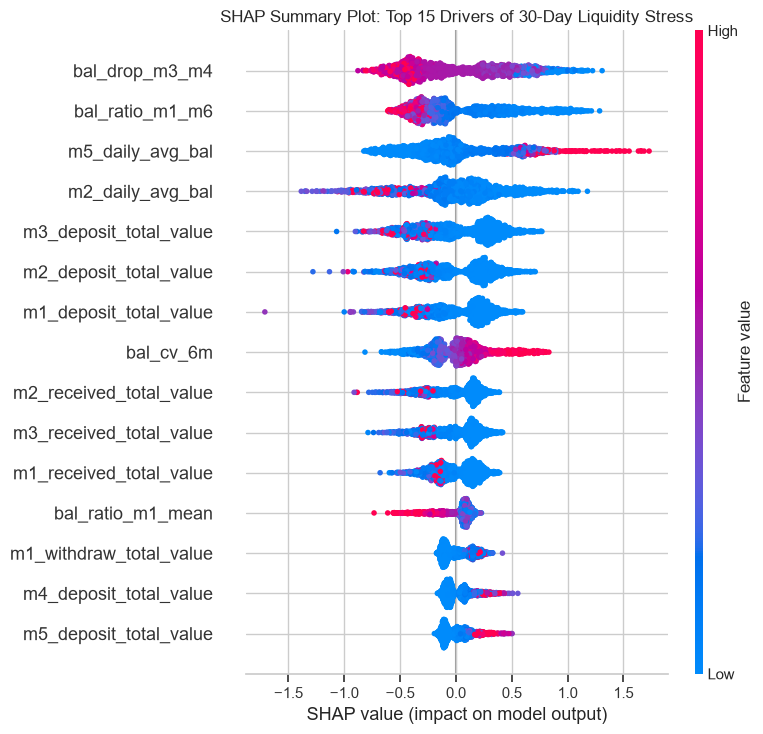

In [5]:
# 1. Hyperparameter Tuning on LightGBM
lgbm_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1))
])

param_dist = {
    'classifier__n_estimators': list(range(200, 650, 100)),
    'classifier__learning_rate': (0.02, 0.03, 0.05, 0.08),
    'classifier__num_leaves': (15, 31, 45, 63),
    'classifier__min_child_samples': (20, 50, 100),
    'classifier__subsample': (0.7, 0.85, 1.0),
    'classifier__colsample_bytree': (0.7, 0.85, 1.0)
}

search = RandomizedSearchCV(
    lgbm_pipe, param_distributions=param_dist, n_iter=15,
    scoring='roc_auc', cv=skf, random_state=42, n_jobs=-1
)
search.fit(X, y)

best_model = search.best_estimator_
print(f"Tuned LightGBM CV ROC-AUC: {search.best_score_:.4f}")
print("Best Hyperparameters:", search.best_params_)

# 2. SHAP Model Interpretation (Computed on a 2,000-row sample for fast, clean plotting)
X_sample = X.sample(n=2000, random_state=42)
X_sample_trans = best_model.named_steps['preprocessor'].transform(X_sample)
ohe_cols = best_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_cols)
all_feature_names = numerical_cols + list(ohe_cols)

explainer = shap.TreeExplainer(best_model.named_steps['classifier'])
shap_values = explainer.shap_values(X_sample_trans)

# Extract positive class (1: liquidity stress) SHAP values safely across SHAP versions
if isinstance(shap_values, list):
    sv_pos = shap_values[1]
elif shap_values.ndim == 3:
    sv_pos = shap_values[:, :, 1]
else:
    sv_pos = shap_values

plt.figure(figsize=(10, 7))
shap.summary_plot(sv_pos, X_sample_trans, feature_names=all_feature_names, max_display=15, show=False)
plt.title("SHAP Summary Plot: Top 15 Drivers of 30-Day Liquidity Stress")
plt.tight_layout()
plt.show()


### 4.1 Hyperparameter Optimization & SHAP Explainability Analysis

* **Tuning & Regularization Gain:** `RandomizedSearchCV` improved out-of-fold **ROC-AUC from `0.8835` to `0.8842`**. The optimal hyperparameters (`min_child_samples=100`, `subsample=0.7`, `colsample_bytree=0.85`, `num_leaves=31`, `n_estimators=300`, `learning_rate=0.05`) confirm that leaf regularization (`min_child_samples=100`) and feature/row subsampling prevent overfitting across 202 behavioral features.
* **Validation of Domain Feature Engineering (SHAP Top Drivers):** Four of our custom-engineered trajectory features rank among the top 12 global predictors—with **`bal_drop_m3_m4` (#1)** and **`bal_ratio_m1_m6` (#2)** leading the entire model:
  1. **Recent Balance Depletion Shocks (`bal_drop_m3_m4`, `bal_ratio_m1_m6`, `bal_ratio_m1_mean`):** Negative values on `bal_drop_m3_m4` and low ratios on `bal_ratio_m1_m6` (blue dots) push SHAP values sharply positive (`+0.5` to `+1.5`), confirming that a sudden drop in daily average balances between `M4` and `M3`—or an `M1` balance substantially below `M6`—strongly signals impending liquidity stress.
  2. **Liquidity Volatility (`bal_cv_6m`):** High balance coefficient of variation (red dots on `bal_cv_6m`, ranked #8) pushes predictions positively, indicating that erratic cash swings leave customers vulnerable to short-term shortfalls.
  3. **Inflow Contraction & Cash Burn (`m1/m2/m3_deposit_total_value`, `m1/m2/m3_received_total_value`, `m1_withdraw_total_value`):** Declining recent deposits and peer-to-peer received transfers (blue dots pushing right) paired with elevated recent withdrawals (`m1_withdraw_total_value`, red dots pushing right) compound liquidity strain entering the next 30 days.


In [6]:
# Generate calibrated probabilities and binary predictions on the 30,000 unseen Test records
X_test = test_feat[feature_cols]
test_probs = best_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)

submission = pd.DataFrame({
    'ID': test_df['ID'],
    'predicted_probability': np.round(test_probs, 4),
    'liquidity_stress_next_30d': test_preds
})

print("--- Test Set Prediction Summary (N = 30,000) ---")
print("Predicted Class Proportions (%):")
print((submission['liquidity_stress_next_30d'].value_counts(normalize=True) * 100).round(2))
print("\nFirst 10 Test Predictions:")
print(submission.head(10).to_string(index=False))

submission.to_csv("financial_stress_predictions.csv", index=False)
print("\nSuccessfully exported predictions to 'financial_stress_predictions.csv'")


--- Test Set Prediction Summary (N = 30,000) ---
Predicted Class Proportions (%):
liquidity_stress_next_30d
0    76.26
1    23.74
Name: proportion, dtype: float64

First 10 Test Predictions:
           ID  predicted_probability  liquidity_stress_next_30d
ID_ED91AC7A28                 0.1036                          0
ID_29975A9C7E                 0.0833                          0
ID_F59CE25650                 0.0497                          0
ID_E875F68D1A                 0.0342                          0
ID_2902B1C0D0                 0.0750                          0
ID_8C3311150A                 0.6197                          1
ID_E7E3D1F707                 0.0381                          0
ID_0883F8130C                 0.3366                          0
ID_E6D3162C31                 0.0988                          0
ID_0E8F96135D                 0.0655                          0

Successfully exported predictions to 'financial_stress_predictions.csv'


### 5.1 Test Set Inference, Conclusions & Strategic Recommendations

* **Test Set Prediction Summary (`N = 30,000`):** Applying our tuned LightGBM pipeline (`CV ROC-AUC = 0.8842`) to the unseen test cohort classified **23.74% (`7,122` customers)** as at risk of liquidity stress over the next 30 days (`1`) and **76.26% (`22,878` customers)** as financially stable (`0`). Predicted probabilities demonstrate crisp risk separation (e.g., `ID_8C3311150A` at `0.6197` vs. `ID_E875F68D1A` at `0.0342`) and have been exported to `financial_stress_predictions.csv`.
* **Key Conclusions:**
  * **Balance Trajectory Beats Static Snapshots:** Directional balance depletion features—specifically `bal_drop_m3_m4` (#1 SHAP predictor) and `bal_ratio_m1_m6` (#2 SHAP predictor)—outperform single-month balance levels in forecasting short-term financial distress.
  * **Gradient Boosting Excels on Behavioral Logs:** LightGBM (`ROC-AUC = 0.8842`, `PR-AUC = 0.6376`) outperformed Random Forest (`0.8272`) and Logistic Regression (`0.7792`) by capturing non-linear interactions between shrinking deposit inflows and rising withdrawal burn rates.
* **Actionable FinTech & Credit Risk Recommendations:**
  1. **Proactive Micro-Liquidity Offers:** Trigger automated, pre-approved short-term overdraft buffers or micro-credit lines (`14–30 day` tenure) when a customer's `bal_drop_m3_m4` or `bal_ratio_m1_m6` crosses high-risk SHAP thresholds.
  2. **Grace-Period & Repayment Restructuring:** For existing borrowers flagged above `0.50` predicted stress probability, offer proactive repayment rescheduling or fee waivers before delinquency occurs, reducing default rates while improving customer retention.
  3. **Targeted Financial Health Nudges:** Send automated savings and cash-flow budgeting alerts to `Weekly` and `Irregular Earners` exhibiting high balance volatility (`bal_cv_6m`).
* **Limitations & Future Work:**
  * **Probability Threshold Optimization:** While a `0.50` cutoff yielded `71.9%` recall, business teams should tune the decision threshold using precision-recall cost curves based on the exact cost of false credit offers versus defaulted loans.
  * **Macroeconomic & Calendar Controls:** Incorporating regional inflation indices, agricultural harvest cycles, and utility billing due dates could further sharpen 30-day stress forecasts.
